Dense M1b (alpha=1.0, Gaussian noise): M3-final-style panels
1. Location error: asymmetric-error line plot


/tmp/ipykernel_1137428/2007136972.py:64: RuntimeWarning: Mean of empty slice
  means = np.nanmean(values, axis=1)
/tmp/ipykernel_1137428/2007136972.py:55: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data, axis=1)
/scratch/ga442/miniforge3/envs/weighted-erm/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1620: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


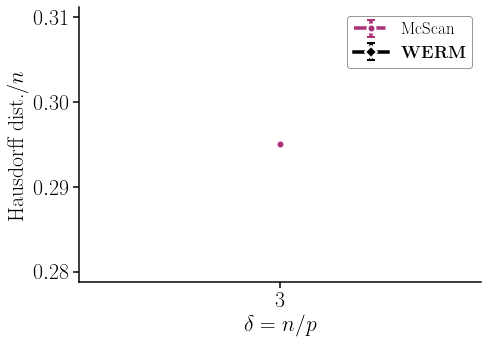

2. Location error: boxplot + deterministic raw-point jitter


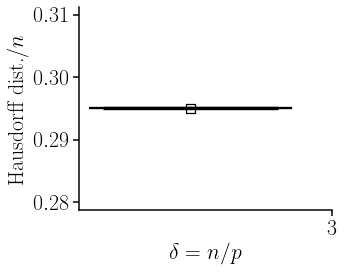

3. Number of change points: asymmetric-error line plot


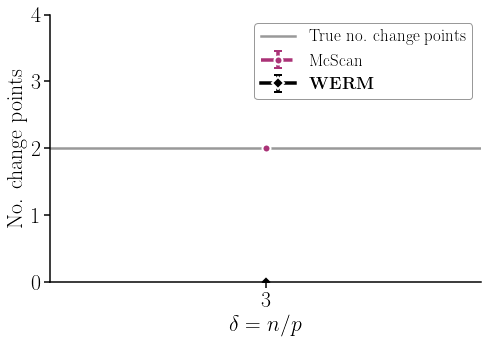

4. Number of change points: boxplot + deterministic raw-point jitter


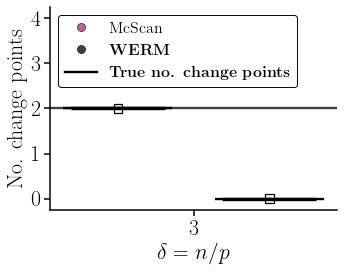

5. Runtime: asymmetric-error line plot


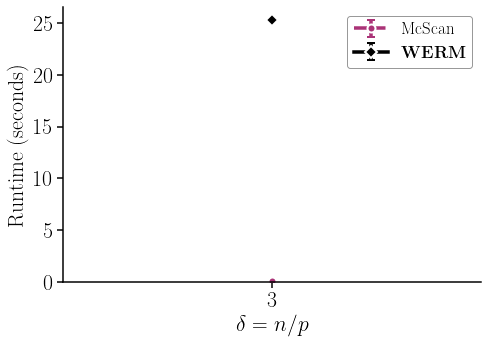

6. Runtime: boxplot + deterministic raw-point jitter


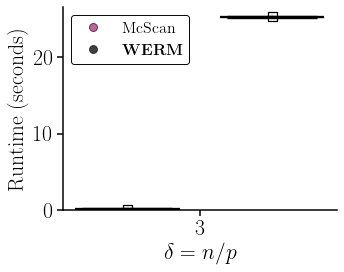

(<Figure size 360x288 with 1 Axes>,
 <Axes: xlabel='$\\delta = n/p$', ylabel='Runtime (seconds)'>,
 [{'metric': 'Runtime (seconds)',
   'method': 'McScan',
   'delta_value': 3.0,
   'n': 1,
   'n_unique': 1,
   'min': 0.0579075813293457,
   'q05': 0.0579075813293457,
   'q25': 0.0579075813293457,
   'median': 0.0579075813293457,
   'q75': 0.0579075813293457,
   'q95': 0.0579075813293457,
   'max': 0.0579075813293457,
   'iqr': 0.0,
   'collapsed': True},
  {'metric': 'Runtime (seconds)',
   'method': 'WERM-unp-10fold',
   'delta_value': 3.0,
   'n': 1,
   'n_unique': 1,
   'min': 25.305354356765747,
   'q05': 25.305354356765747,
   'q25': 25.305354356765747,
   'median': 25.305354356765747,
   'q75': 25.305354356765747,
   'q95': 25.305354356765747,
   'max': 25.305354356765747,
   'iqr': 0.0,
   'collapsed': True}])

In [1]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt

plt.switch_backend("module://matplotlib_inline.backend_inline")
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',
    'pgf.preamble': r'\usepackage{amsmath}\usepackage{amsfonts}\usepackage{amssymb}\usepackage{siunitx}',
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': True,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1,
})

FINAL_RESULT_FILE = "results/M1_upsample_final_alpha10_dense_gaussian_ls_seed46_100trials.pkl"
if os.environ.get("WERM_SMOKE") == "1":
    FINAL_RESULT_FILE = FINAL_RESULT_FILE.replace(".pkl", "_smoke.pkl")
with open(FINAL_RESULT_FILE, "rb") as handle:
    _payload = pickle.load(handle)
results = _payload["results"]
_params = _payload["params"]
p, L = _params["p"], _params["L"]
delta_list = np.asarray(_params["delta_list"], dtype=float)
fractional_chgpt_locations = np.asarray(_params["fractional_chgpt_locations"])

methods_to_evaluate = [
    dict(name='McScan', label=r'McScan', color='#AA3377', marker='o', linestyle='--'),
    dict(name='WERM-unp-10fold', label=r'\textbf{WERM}', color='black', marker='D', linestyle='-'),
]
method_names_list = [method['name'] for method in methods_to_evaluate]
for method_name in method_names_list:
    _size = np.asarray(results[f'size_{method_name}'], dtype=float)
    _haus = np.asarray(results[f'haus_{method_name}'], dtype=float)
    results[f'haus_{method_name}'] = np.where(_size > 0, _haus, np.nan)

def get_asymmetric_errors(data):
    data = np.asarray(data, dtype=float)
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    return [np.abs(means - p25), np.abs(p75 - means)]

def _plot_asymmetric_metric(metric, ylabel, reference_y=None, y_limits=None):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    for method in methods_to_evaluate:
        values = np.asarray(results[f'{metric}_{method["name"]}'], dtype=float)
        means = np.nanmean(values, axis=1)
        ax.errorbar(
            delta_list, means, yerr=get_asymmetric_errors(values),
            label=method['label'], marker=method['marker'], ls=method['linestyle'],
            color=method['color'], capsize=4, capthick=2, markersize=8,
            linewidth=3.5, markeredgewidth=2, markeredgecolor='white',
        )
    if reference_y is not None:
        ax.axhline(reference_y, color='gray', linestyle='-', linewidth=2.5,
                   alpha=0.8, label=r'True no. change points')
    if y_limits is not None:
        ax.set_ylim(*y_limits)
    ax.set_xlabel(r'$\delta = n/p$', fontsize=22)
    ax.set_ylabel(ylabel, fontsize=22)
    ax.set_xticks(delta_list[::2])
    ax.set_xticklabels([f'{value:.0f}' for value in delta_list[::2]], fontsize=22)
    ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=22)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 17}, fancybox=True, framealpha=0.4)
    fig.tight_layout()
    plt.show()
    return fig, ax

def plot_size_asymmetric_errors():
    return _plot_asymmetric_metric(
        'size', r'No. change points',
        reference_y=len(fractional_chgpt_locations), y_limits=(0, L),
    )

def plot_location_asymmetric_errors():
    return _plot_asymmetric_metric('haus', r'Hausdorff dist./$n$')

def plot_runtime_asymmetric_errors():
    return _plot_asymmetric_metric('runtime', r'Runtime (seconds)', y_limits=(0, None))

x_y_label_fontsize = 22

# --- Distribution Plotting Functions -----------------------------------------
#
# Three display modes are supported:
#   1. "box_jitter"      : standard boxplot + all observations (recommended)
#   2. "interval_jitter" : 5--95%, IQR, median + all observations
#   3. "violin_jitter"   : violin + IQR/median + all observations
#
# A box with Q1 == Q3 is statistically supposed to collapse.  We therefore do
# not artificially change its quartiles.  Instead, collapsed IQRs are reinforced
# with a thick horizontal line and, optionally, a hollow-square glyph.

from matplotlib.lines import Line2D


_DISTRIBUTION_STYLES = {"box_jitter", "interval_jitter", "violin_jitter"}
_COLLAPSED_STYLES = {"line", "line_and_marker", "none"}


def _finite_1d(values):
    """Return a flattened float array containing only finite observations."""
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]


def _distribution_summary(values):
    """Compute the summaries used by all distribution-plotting modes."""
    values = _finite_1d(values)
    if values.size == 0:
        return None

    q05, q25, median, q75, q95 = np.percentile(
        values, [5, 25, 50, 75, 95]
    )
    data_scale = max(
        1.0,
        float(np.max(np.abs(values))),
        float(np.ptp(values)),
    )
    collapsed = np.isclose(
        q25,
        q75,
        rtol=1e-10,
        atol=1e-12 * data_scale,
    )

    return {
        "n": int(values.size),
        "n_unique": int(np.unique(values).size),
        "min": float(np.min(values)),
        "q05": float(q05),
        "q25": float(q25),
        "median": float(median),
        "q75": float(q75),
        "q95": float(q95),
        "max": float(np.max(values)),
        "iqr": float(q75 - q25),
        "collapsed": bool(collapsed),
    }


def _warn(message):
    """Use the project logger when it supports warnings; otherwise print."""
    logger = globals().get("main_logger")
    warning_method = getattr(logger, "warning", None)
    if callable(warning_method):
        warning_method(message)
    else:
        print(f"WARNING: {message}")


def _jittered_x(position, n, rng, jitter_width):
    """Generate reproducible horizontal jitter without changing y values."""
    if n <= 1 or jitter_width <= 0:
        return np.full(n, position, dtype=float)
    return position + rng.uniform(-jitter_width, jitter_width, size=n)


def _draw_raw_points(
    ax,
    values,
    position,
    color,
    rng,
    jitter_width=0.18,
    point_size=22,
    point_alpha=0.16,
):
    """Overlay all observations using x-only jitter."""
    x = _jittered_x(position, values.size, rng, jitter_width)
    ax.scatter(
        x,
        values,
        s=point_size,
        facecolor=color,
        edgecolor="none",
        alpha=point_alpha,
        zorder=4,
        clip_on=True,
        label="_nolegend_",
    )


def _draw_collapsed_iqr(
    ax,
    position,
    median,
    box_width,
    collapsed_style="line_and_marker",
):
    """
    Make a zero-IQR group visible without inventing a nonzero statistical box.

    The optional square is a display glyph only; it does not encode an interval.
    """
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )
    if collapsed_style == "none":
        return

    half_width = 0.43 * box_width
    ax.plot(
        [position - half_width, position + half_width],
        [median, median],
        color="black",
        linewidth=3.4,
        solid_capstyle="butt",
        zorder=7,
        label="_nolegend_",
    )

    if collapsed_style == "line_and_marker":
        ax.scatter(
            [position],
            [median],
            marker="s",
            s=72,
            facecolor="none",
            edgecolor="black",
            linewidth=1.25,
            zorder=8,
            label="_nolegend_",
        )


def _draw_box_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw one honest boxplot and overlay all observations."""
    bp = ax.boxplot(
        [values],
        positions=[position],
        widths=box_width,
        patch_artist=True,
        showfliers=False,       # every observation is shown by the scatter layer
        whis=1.5,
        autorange=True,         # if IQR=0, extend whiskers to min/max
        manage_ticks=False,
        medianprops={
            "color": "black",
            "linewidth": 2.3,
            "zorder": 6,
        },
        boxprops={
            "color": "black",
            "linewidth": 1.35,
            "zorder": 2,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
        capprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
    )

    patch = bp["boxes"][0]
    patch.set_facecolor(color)
    patch.set_alpha(0.28)
    patch.set_edgecolor("black")

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )

    # Reinforce the statistical line when the box height is genuinely zero.
    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_summary(
    ax,
    position,
    color,
    summary,
    box_width,
    collapsed_style,
):
    """Draw 5--95%, IQR, and median summaries."""
    cap_half_width = 0.14 * box_width

    # Thin 5--95% interval and end caps.
    ax.vlines(
        position,
        summary["q05"],
        summary["q95"],
        color="black",
        linewidth=1.35,
        zorder=5,
    )
    ax.hlines(
        [summary["q05"], summary["q95"]],
        position - cap_half_width,
        position + cap_half_width,
        color="black",
        linewidth=1.35,
        zorder=5,
    )

    # Thick IQR interval. It correctly becomes a point/line when IQR=0.
    ax.vlines(
        position,
        summary["q25"],
        summary["q75"],
        color=color,
        linewidth=8.0,
        alpha=0.58,
        zorder=5,
    )

    # Median remains visible even when every interval collapses.
    ax.scatter(
        [position],
        [summary["median"]],
        marker="D",
        s=46,
        facecolor=color,
        edgecolor="black",
        linewidth=0.9,
        zorder=7,
        label="_nolegend_",
    )

    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw raw observations together with quantile intervals and the median."""
    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _draw_violin_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """
    Draw a violin/raincloud-style display plus points and quantile summaries.

    The violin is omitted when there are fewer than two distinct observations,
    because a kernel density is then undefined/uninformative.
    """
    if values.size >= 2 and summary["n_unique"] >= 2:
        parts = ax.violinplot(
            [values],
            positions=[position],
            widths=1.15 * box_width,
            showmeans=False,
            showmedians=False,
            showextrema=False,
            points=100,
            bw_method="scott",
        )
        body = parts["bodies"][0]
        body.set_facecolor(color)
        body.set_edgecolor("black")
        body.set_linewidth(1.0)
        body.set_alpha(0.20)
        body.set_zorder(1)

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _format_distribution_diagnostic(metric_label, method_name, delta, summary):
    return (
        f"{metric_label}; method={method_name}; delta^2={delta:g}: "
        f"n={summary['n']}, unique={summary['n_unique']}, "
        f"min={summary['min']:.6g}, Q1={summary['q25']:.6g}, "
        f"median={summary['median']:.6g}, Q3={summary['q75']:.6g}, "
        f"max={summary['max']:.6g}, IQR={summary['iqr']:.6g}, "
        f"collapsed={summary['collapsed']}"
    )


def _plot_grouped_distributions(
    current_delta_list,
    current_results,
    methods_to_evaluate,
    metric_prefix,
    metric_label,
    y_label,
    filename_base,
    filename_metric,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    random_seed=2026,
    box_width=0.72,
    jitter_width=0.20,
    point_size=22,
    point_alpha=0.16,
    diagnostics=False,
    show_legend=True,
    legend_loc="upper left",
    y_limits=None,
    y_ticks=None,
    reference_y=None,
    reference_label=None,
    x_label=r'$\delta = n/p$',
    tick_label_format=".0f",
    tick_stride=1,
):
    """Shared implementation for location, size, and runtime distributions."""
    if plot_style not in _DISTRIBUTION_STYLES:
        raise ValueError(
            f"plot_style must be one of {sorted(_DISTRIBUTION_STYLES)}, "
            f"got {plot_style!r}."
        )
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )

    fig, ax = plt.subplots(1, 1, figsize=(5.0, 4.0))
    rng = np.random.default_rng(random_seed)

    plot_labels = [method["label"] for method in methods_to_evaluate]
    plot_colors = [method["color"] for method in methods_to_evaluate]
    methods = [method["name"] for method in methods_to_evaluate]

    spacing = len(methods) + 1
    diagnostic_records = []

    for delta_idx, delta in enumerate(current_delta_list):
        for method_idx, method_name in enumerate(methods):
            data = current_results.get(f"{metric_prefix}_{method_name}")
            if data is None or data.ndim < 2 or data.shape[0] <= delta_idx:
                _warn(
                    f"No {metric_label} data for {method_name} at "
                    f"delta^2={delta:g}; skipping this group."
                )
                continue

            values = _finite_1d(data[delta_idx, :])
            if values.size == 0:
                _warn(
                    f"No finite {metric_label} observations for {method_name} "
                    f"at delta^2={delta:g}; skipping this group."
                )
                continue

            summary = _distribution_summary(values)
            position = delta_idx * spacing + method_idx
            color = plot_colors[method_idx]

            record = {
                "metric": metric_label,
                "method": method_name,
                "delta_value": float(delta),
                **summary,
            }
            diagnostic_records.append(record)
            if diagnostics:
                print(
                    _format_distribution_diagnostic(
                        metric_label, method_name, delta, summary
                    )
                )

            draw_kwargs = dict(
                ax=ax,
                values=values,
                position=position,
                color=color,
                rng=rng,
                summary=summary,
                box_width=box_width,
                jitter_width=jitter_width,
                point_size=point_size,
                point_alpha=point_alpha,
                collapsed_style=collapsed_style,
            )

            if plot_style == "box_jitter":
                _draw_box_jitter_group(**draw_kwargs)
            elif plot_style == "interval_jitter":
                _draw_interval_jitter_group(**draw_kwargs)
            else:
                _draw_violin_jitter_group(**draw_kwargs)

    # Optional horizontal truth/reference line.
    if reference_y is not None:
        ax.axhline(
            y=reference_y,
            color="black",
            linestyle="-",
            linewidth=2.4,
            alpha=0.75,
            zorder=0,
            label="_nolegend_",
        )

    delta_positions = [
        i * spacing + (len(methods) - 1) / 2
        for i in range(len(current_delta_list))
    ]
    tick_indices = np.arange(0, len(current_delta_list), tick_stride, dtype=int)
    ax.set_xticks([delta_positions[i] for i in tick_indices])
    ax.set_xticklabels(
        [format(float(current_delta_list[i]), tick_label_format) for i in tick_indices]
    )
    ax.set_xlabel(x_label, fontsize=x_y_label_fontsize)
    ax.set_ylabel(y_label, fontsize=x_y_label_fontsize)

    if y_limits is not None:
        ax.set_ylim(*y_limits)
    if y_ticks is not None:
        ax.set_yticks(y_ticks)

    if show_legend:
        legend_elements = [
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="none",
                markersize=8,
                markerfacecolor=plot_colors[i],
                markeredgecolor="black",
                markeredgewidth=0.8,
                alpha=0.75,
                label=plot_labels[i],
            )
            for i in range(len(methods))
        ]
        if reference_y is not None and reference_label is not None:
            legend_elements.append(
                Line2D(
                    [0],
                    [0],
                    color="black",
                    linewidth=2.4,
                    label=reference_label,
                )
            )
        ax.legend(
            handles=legend_elements,
            loc=legend_loc,
            fontsize=16,
            frameon=True,
            edgecolor="black",
            framealpha=0.95,
        )

    ax.tick_params(
        axis="both",
        which="major",
        width=1.5,
        length=6,
        labelsize=x_y_label_fontsize,
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)

    # Keep the historical filenames for the recommended box+jitter mode.
    style_suffix = {
        "box_jitter": "boxplots",
        "interval_jitter": "interval_jitter",
        "violin_jitter": "violin_jitter",
    }[plot_style]
    output_stem = f"{filename_base}_{filename_metric}_{style_suffix}"

    fig.tight_layout()



    plt.show()

    return fig, ax, diagnostic_records


def plot_location_boxplots(
    current_delta_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot the Hausdorff-error distributions.

    Recommended publication mode: plot_style="box_jitter".
    Clean alternative:             plot_style="interval_jitter".
    """
    return _plot_grouped_distributions(
        current_delta_list=current_delta_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="haus",
        metric_label="Hausdorff distance / n",
        y_label=r'Hausdorff dist./$n$',
        filename_base=filename_base,
        filename_metric="location",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=False,
        tick_label_format=".0f",
        tick_stride=2,
        x_label=r'$\delta = n/p$',
    )


def plot_size_boxplots(
    current_delta_list,
    current_results,
    methods_to_evaluate,
    L,
    fractional_chgpt_locations,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot estimated changepoint counts.

    Because this response is discrete, box+jitter or interval+jitter is preferable
    to a violin plot, whose kernel smoothing can imply nonexistent values.
    """
    return _plot_grouped_distributions(
        current_delta_list=current_delta_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="size",
        metric_label="Number of change points",
        y_label=r'No. change points',
        filename_base=filename_base,
        filename_metric="size",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(-0.25, L + 0.25),
        y_ticks=np.arange(0, L + 1, dtype=int),
        reference_y=len(fractional_chgpt_locations),
        reference_label=r'\textbf{True no. change points}',
        tick_label_format=".0f",
        x_label=r'$\delta = n/p$',
    )


def plot_runtime_boxplots(
    current_delta_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """Plot runtime distributions using any supported display mode."""
    return _plot_grouped_distributions(
        current_delta_list=current_delta_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="runtime",
        metric_label="Runtime (seconds)",
        y_label=r'Runtime (seconds)',
        filename_base=filename_base,
        filename_metric="runtime",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(0, None),
        tick_label_format=".0f",
        x_label=r'$\delta = n/p$',
    )



print('Dense M1b (alpha=1.0, Gaussian noise): M3-final-style panels')
print("1. Location error: asymmetric-error line plot")
plot_location_asymmetric_errors()
print("2. Location error: boxplot + deterministic raw-point jitter")
plot_location_boxplots(
    delta_list, results, methods_to_evaluate, "M1_dense_final",
    plot_style="box_jitter", collapsed_style="line_and_marker",
)
print("3. Number of change points: asymmetric-error line plot")
plot_size_asymmetric_errors()
print("4. Number of change points: boxplot + deterministic raw-point jitter")
plot_size_boxplots(
    delta_list, results, methods_to_evaluate, L, fractional_chgpt_locations,
    "M1_dense_final", plot_style="box_jitter", collapsed_style="line_and_marker",
)
print("5. Runtime: asymmetric-error line plot")
plot_runtime_asymmetric_errors()
print("6. Runtime: boxplot + deterministic raw-point jitter")
plot_runtime_boxplots(
    delta_list, results, methods_to_evaluate, "M1_dense_final",
    plot_style="box_jitter", collapsed_style="line_and_marker",
)
